# Fase 4: Evaluación end-to-end sobre el conjunto de Test

Entrena con el conjunto de **Training Data** (o el subconjunto que ya venías usando) y evalúa sobre **Test Data** de ISIC 2016 — el modelo nunca ve estas imágenes durante entrenamiento. Reconstruye la máscara predicha por imagen, la compara contra el ground-truth real con IoU/Dice/precisión/recall, y muestra los resultados visual y numéricamente.

### Setup

In [1]:
import sys; sys.path.append('..')

from src.io_utils import cargar_imagen, cargar_mascara, listar_pares_imagen_mascara
from src.presegmentation import presegmentar_superpixeles
from src.quaternion_qft import procesar_qft_superpixeles
from src.feature_extraction import extraer_matriz_caracteristicas, normalizar_caracteristicas
from src.classification import etiquetar_superpixeles, entrenar_modelo, predecir
from src.evaluation import reconstruir_mascara, calcular_metricas

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

N_SEGMENTOS = 100
UMBRAL_ETIQUETADO = 0.5


TIPO_MODELO = "random_forest"   # cambia según lo que decidieron con fase3

pares_train = listar_pares_imagen_mascara('../data/raw/train', '../data/masks/train')
pares_test = listar_pares_imagen_mascara('../data/raw/test', '../data/masks/test')

print("Imágenes de entrenamiento disponibles:", len(pares_train))
print("Imágenes de test disponibles:", len(pares_test))

Imágenes de entrenamiento disponibles: 900
Imágenes de test disponibles: 379


## 1. Entrenar el modelo final

Usa un subconjunto de train (ajusta `N_TRAIN`) — sube el número una vez que confirmes que corre bien.

In [2]:
from joblib import Parallel, delayed
from tqdm.notebook import tqdm
import numpy as np
from sklearn.ensemble import RandomForestClassifier

N_TRAIN = len(pares_train)  # Usa todo el dataset de entrenamiento (900 imágenes)

def procesar_par_train(par):
    ruta_img, ruta_mask = par
    try:
        img = cargar_imagen(ruta_img)
        mask = cargar_mascara(ruta_mask)
        regiones = presegmentar_superpixeles(img, n_segmentos=N_SEGMENTOS)
        espectros = procesar_qft_superpixeles(img, regiones)
        X_img = extraer_matriz_caracteristicas(espectros)
        y_img = etiquetar_superpixeles(regiones, mask, umbral=UMBRAL_ETIQUETADO)
        return X_img, y_img
    except Exception as e:
        return None, (ruta_img, str(e))

print(f"🚀 Procesando {N_TRAIN} imágenes de entrenamiento en paralelo (12 hilos)...")

# 'tqdm' genera una sola barra de progreso visual limpia que no satura la pantalla
resultados_raw = Parallel(n_jobs=-1)(
    delayed(procesar_par_train)(par) 
    for par in tqdm(pares_train[:N_TRAIN], desc="Entrenamiento QFT+SLIC")
)

# Filtrar resultados válidos
X_list, y_list, fallidas = [], [], []
for res_x, res_y in resultados_raw:
    if res_x is None:
        fallidas.append(res_y)
    else:
        X_list.append(res_x)
        y_list.append(res_y)

if fallidas:
    print(f"⚠️ {len(fallidas)} imágenes fallaron durante el entrenamiento:")
    for ruta, err in fallidas:
        print(f"   {ruta}: {err}")

X_train = np.vstack(X_list)
y_train = np.concatenate(y_list)
X_train_norm = normalizar_caracteristicas(X_train, metodo='zscore')

# Entrenar el clasificador usando todos los núcleos del procesador
modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
modelo.fit(X_train_norm, y_train)

print(f"✅ Modelo '{TIPO_MODELO}' entrenado exitosamente con {X_train.shape[0]} superpíxeles de {N_TRAIN} imágenes.")


🚀 Procesando 900 imágenes de entrenamiento en paralelo (12 hilos)...


Entrenamiento QFT+SLIC:   0%|          | 0/900 [00:00<?, ?it/s]

✅ Modelo 'random_forest' entrenado exitosamente con 94991 superpíxeles de 900 imágenes.


## 2. Evaluar sobre el conjunto de Test, imagen por imagen

Para cada imagen de test: presegmenta, calcula QFT y características, predice por superpíxel, reconstruye la máscara completa, y compara contra el ground-truth real.

In [3]:
from joblib import Parallel, delayed
from tqdm.notebook import tqdm
import pandas as pd

N_TEST = len(pares_test)  # Evalúa sobre todo el dataset de prueba (379 imágenes)

def evaluar_par_test(par):
    ruta_img, ruta_mask = par
    try:
        img = cargar_imagen(ruta_img)
        mask_real = cargar_mascara(ruta_mask)

        regiones = presegmentar_superpixeles(img, n_segmentos=N_SEGMENTOS)
        espectros = procesar_qft_superpixeles(img, regiones)
        X_img = extraer_matriz_caracteristicas(espectros)
        X_img_norm = normalizar_caracteristicas(X_img, metodo='zscore')

        y_pred = predecir(modelo, X_img_norm)
        mask_pred = reconstruir_mascara(regiones, y_pred, forma=img.shape[:2])

        metricas = calcular_metricas(mask_pred, mask_real)
        metricas["imagen"] = ruta_img.replace('\\', '/').split('/')[-1]
        return metricas
    except Exception as e:
        return None

print(f"🚀 Evaluando {N_TEST} imágenes de test en paralelo (12 hilos)...")

# 'tqdm' muestra la barra de progreso para el conjunto de test
resultados_raw = Parallel(n_jobs=-1)(
    delayed(evaluar_par_test)(par) 
    for par in tqdm(pares_test[:N_TEST], desc="Evaluación Test")
)

resultados_por_imagen = [r for r in resultados_raw if r is not None]

df_resultados = pd.DataFrame(resultados_por_imagen)
df_resultados = df_resultados[["imagen", "iou", "dice", "precision", "recall"]]
df_resultados


🚀 Evaluando 379 imágenes de test en paralelo (12 hilos)...


Evaluación Test:   0%|          | 0/379 [00:00<?, ?it/s]

,imagen,iou,dice,precision,recall
0,ISIC_0000003.jpg,0.378140,0.548769,0.839783,0.407542
1,ISIC_0000012.jpg,0.000818,0.001635,0.001217,0.002489
2,ISIC_0000013.jpg,0.005192,0.010331,0.061976,0.005635
3,ISIC_0000014.jpg,0.458200,0.628446,0.804331,0.515681
4,ISIC_0000015.jpg,0.249316,0.399124,0.472633,0.345402
...,...,...,...,...,...
374,ISIC_0011367.jpg,0.033780,0.065353,0.046374,0.110627
375,ISIC_0011374.jpg,0.170181,0.290862,0.997762,0.170246
376,ISIC_0011384.jpg,0.322058,0.487207,0.607867,0.406514
377,ISIC_0011386.jpg,0.208784,0.345445,0.290752,0.425483


### Métricas promedio sobre el conjunto de test

In [4]:
resumen = df_resultados[["iou", "dice", "precision", "recall"]].agg(["mean", "std", "min", "max"])
resumen

,iou,dice,precision,recall
mean,0.253037,0.381254,0.562911,0.336846
std,0.148084,0.193536,0.336964,0.164343
min,0.000000,0.000000,0.000000,0.000000
max,0.686117,0.813842,1.000000,0.845413


### Distribución de IoU y Dice por imagen

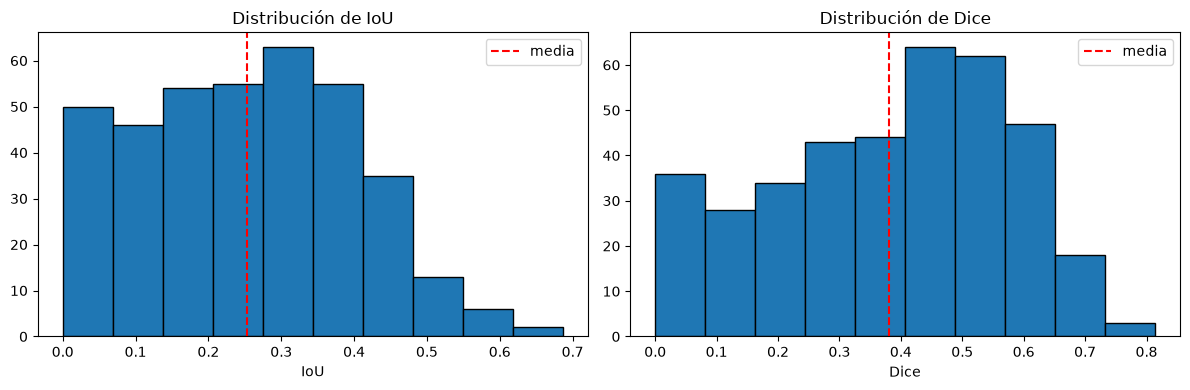

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_resultados["iou"], bins=10, edgecolor="black")
axes[0].axvline(df_resultados["iou"].mean(), color="red", linestyle="--", label="media")
axes[0].set_title("Distribución de IoU")
axes[0].set_xlabel("IoU"); axes[0].legend()

axes[1].hist(df_resultados["dice"], bins=10, edgecolor="black")
axes[1].axvline(df_resultados["dice"].mean(), color="red", linestyle="--", label="media")
axes[1].set_title("Distribución de Dice")
axes[1].set_xlabel("Dice"); axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Visualización lado a lado

Mira el mejor y el peor caso según IoU — ayuda a entender en qué tipo de imágenes falla el modelo (ej. lesiones muy irregulares, bajo contraste, pelo/vello cubriendo la piel).

=== Mejor caso ===


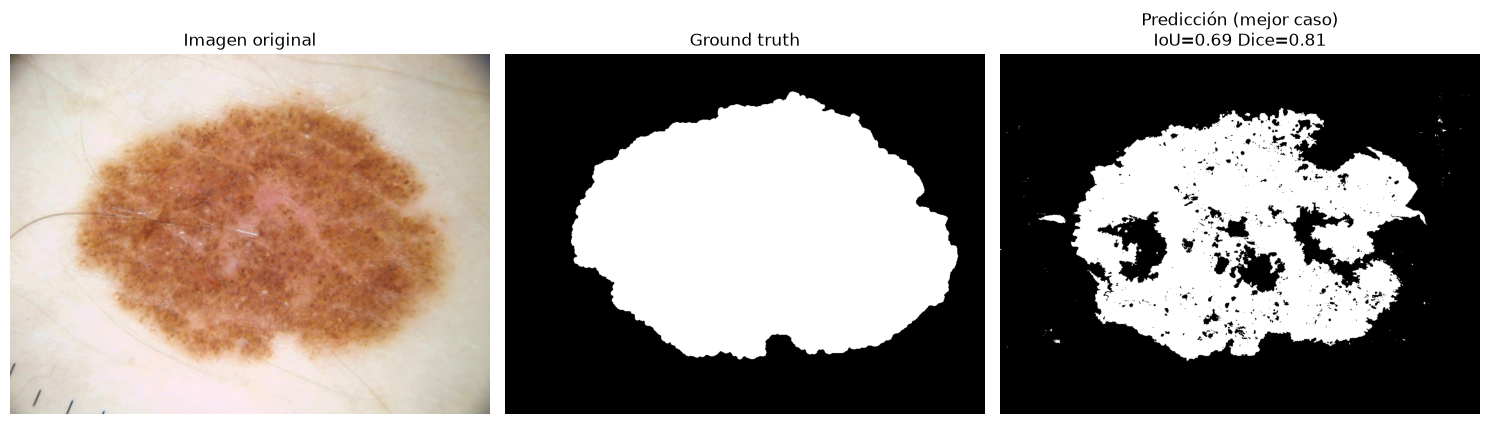

=== Peor caso ===


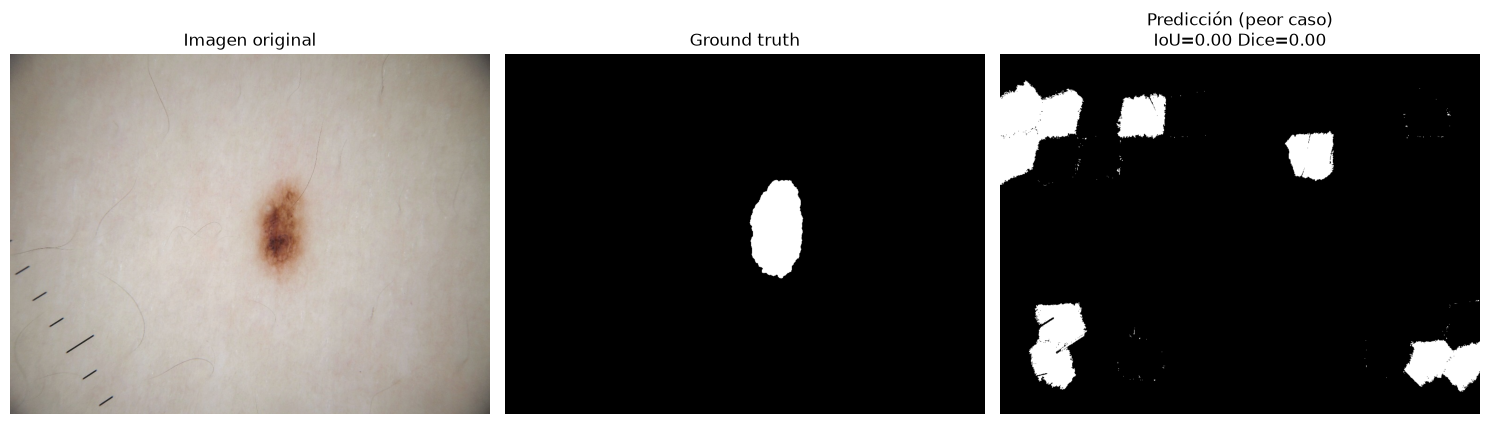

{'iou': 0.0, 'dice': 0.0, 'precision': 0.0, 'recall': 0.0}

In [6]:
def visualizar_resultado(ruta_img, ruta_mask, modelo, n_segmentos, titulo_extra=""):
    img = cargar_imagen(ruta_img)
    mask_real = cargar_mascara(ruta_mask)

    regiones = presegmentar_superpixeles(img, n_segmentos=n_segmentos)
    espectros = procesar_qft_superpixeles(img, regiones)
    X_img = normalizar_caracteristicas(extraer_matriz_caracteristicas(espectros), metodo='zscore')
    y_pred = predecir(modelo, X_img)
    mask_pred = reconstruir_mascara(regiones, y_pred, forma=img.shape[:2])

    metricas = calcular_metricas(mask_pred, mask_real)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img); axes[0].set_title("Imagen original"); axes[0].axis("off")
    axes[1].imshow(mask_real, cmap="gray"); axes[1].set_title("Ground truth"); axes[1].axis("off")
    axes[2].imshow(mask_pred, cmap="gray")
    axes[2].set_title(f"Predicción {titulo_extra}\nIoU={metricas['iou']:.2f} Dice={metricas['dice']:.2f}")
    axes[2].axis("off")
    plt.tight_layout()
    plt.show()
    return metricas

idx_mejor = df_resultados["iou"].idxmax()
idx_peor = df_resultados["iou"].idxmin()

ruta_mejor = pares_test[idx_mejor]
ruta_peor = pares_test[idx_peor]

print("=== Mejor caso ===")
visualizar_resultado(*ruta_mejor, modelo, N_SEGMENTOS, titulo_extra="(mejor caso)")

print("=== Peor caso ===")
visualizar_resultado(*ruta_peor, modelo, N_SEGMENTOS, titulo_extra="(peor caso)")

## Siguiente paso

`df_resultados` y `resumen` ya tienen las tablas listas para pegar en la sección de Experimentación del reporte. Las figuras del mejor/peor caso sirven para la discusión cualitativa de resultados (qué tipo de imágenes son más difíciles para el modelo).

In [7]:
'modelo' in locals()

True